In [6]:
import pandas as pd
import matplotlib.pyplot as plt

In [7]:
merged_df=pd.read_csv('cleaned_orders_data.csv')

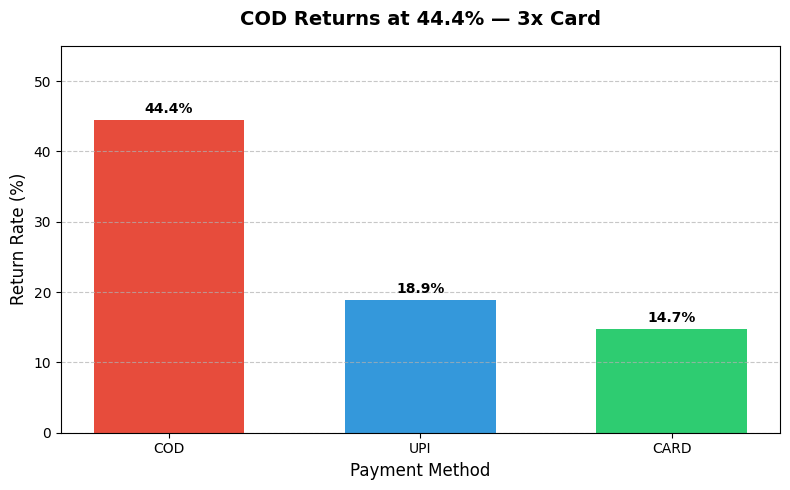

In [8]:
merged_df['order_date'] = pd.to_datetime(merged_df['order_date'])
merged_df['month'] = merged_df['order_date'].dt.to_period('M')

rates = merged_df.groupby('payment_method')['returned'].mean() * 100
rates = rates.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(rates.index, rates.values, color=['#e74c3c', '#3498db', '#2ecc71'], width=0.6)

for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10, fontweight='bold')

ax.set_title('COD Returns at 44.4% — 3x Card', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Payment Method', fontsize=12)
ax.set_ylabel('Return Rate (%)', fontsize=12)
ax.set_ylim(0, 55)
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

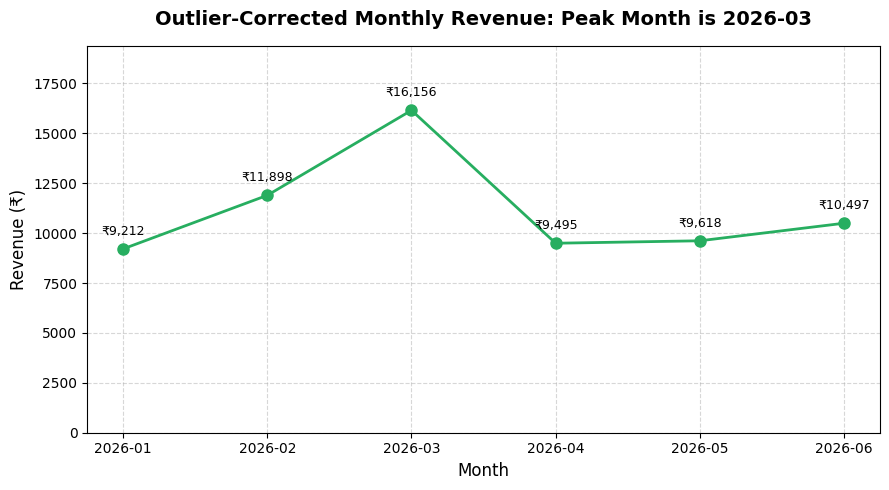

In [9]:

merged_df['order_date'] = pd.to_datetime(merged_df['order_date'])
merged_df['month'] = merged_df['order_date'].dt.to_period('M')

if 'order_value' not in merged_df.columns:
    if 'price' in merged_df.columns and 'quantity' in merged_df.columns:
        merged_df['order_value'] = merged_df['quantity'] * merged_df['price']
    else:
        merged_df['order_value'] = merged_df['quantity']

Q1 = merged_df['order_value'].quantile(0.25)
Q3 = merged_df['order_value'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

filtered_df = merged_df[(merged_df['order_value'] >= lower_bound) & (merged_df['order_value'] <= upper_bound)]

trend_data = filtered_df.groupby('month')['order_value'].sum().sort_index()

x_labels = [str(period) for period in trend_data.index]
y_values = trend_data.values

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x_labels, y_values, marker='o', color='#27ae60', linewidth=2, markersize=8)

for i, txt in enumerate(y_values):
    ax.annotate(f'₹{txt:,.0f}',
                (x_labels[i], y_values[i]),
                textcoords="offset points",
                xytext=(0, 10),
                ha='center', fontsize=9)

ax.set_title('Outlier-Corrected Monthly Revenue: Peak Month is 2026-03', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Month', fontsize=12)
ax.set_ylabel('Revenue (₹)', fontsize=12)
ax.set_ylim(0, max(y_values) * 1.2)
ax.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()